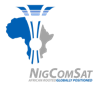 &nbsp;&nbsp; 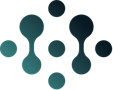

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-4/day-1-scoring-detectors-and-quiz-2/2-exercise/W4D1-exercise.ipynb)

# 🎯 Week 4 · Day 1: Scoring a Detector

**Today:** the answer key comes out. You score every alarm from Week 3 with **one** scorer and **one** set of rules, and then turn false alarms into engineer hours.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W4D1-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _res(x, caught, fa):
    return isinstance(x, dict) and x.get("caught") == caught and x.get("false_alarms") == fa

def _c_a1(x):
    v = float(x)
    v = v / 100 if v > 1 else v
    return _near(v, 1 - 6 / 4706, 0.0002), \
        "99.87%! A detector that NEVER fires looks almost perfect. That's why we never report accuracy for rare events.", \
        "1 minus (events ÷ readings): 1 - n_events / n_readings"

def _c_a2(x):
    ok = str(x[0]).strip().lower() == "yes" and int(x[1]) == 1
    return ok, "Rules agreed: one flag inside = caught, and many flags inside one event = ONE catch.", \
        "Rule 1: one flag anywhere inside counts. Rule 2: two flags inside one event are still one catch."

def _c_a3(x):
    return _near(x[0], 0.9, 0.001) and _near(x[1], 0.045, 0.001), \
        "Recall 0.90, precision 0.045. Musa misses little but wakes the whole estate for nothing. 📢🐐", \
        "recall = caught ÷ real thieves (9 ÷ 10). precision = caught ÷ all shouts (9 ÷ 200)."

def _c_b1(x):
    return _res(x, 0, 18), "18 alarms, 0 real: every one was a normal eclipse night. Correct alarms, useless alarms.", \
        "Use SOC_FLOOR = 82 and score with source_file \"bus_power_telemetry_hourly.csv\"."

def _c_b2(x):
    return _res(x, 3, 46), "Caught all 3 dropouts… plus 46 false alarms, all at 21:00 UTC = eclipse time. 🌘", \
        "K is the number of standard deviations in the band: 3."

def _c_b3(x):
    return _res(x, 3, 0), "3 of 3 caught, ZERO false alarms. One condition on the known cause did it. 🌞", \
        "Sunlit hours have eclipse_flag == 0."

def _c_b4(x):
    return _res(x, 2, 0), "Both amplifier events caught, no false alarms. The residual saw what the raw series hid. 🧮", \
        "Use the same 3-sigma rule on the residual: resid.abs() > 3 * resid_sd"

def _c_b5(x):
    return _res(x, 2, 2), "Same 2 catches as the residual rule, plus 2 false alarms. More sensitive is not free.", \
        "Use the standard decision line H = 5."

def _c_b6(x):
    return str(x).strip().upper() == "EV06", "EV06, the battery's fade speeding up. A change in SLOPE, not in value. Pepper task below! 🌶️", \
        "Look at the report card: which event has nobody's name next to it? It's in the battery file."

def _c_b7(x):
    return int(x) == 3, "Control chart, sunlit only: recall 1.00, precision 1.00. That goes on the console. ✅", \
        "Pick the row with recall 1 and zero false alarms."

def _c_c1(x):
    return _near(x, 46 * 2 * 20 / 60, 0.2), \
        f"About {46 * 2 * 20 / 60:.0f} hours a year, roughly 4 full shifts. Now a manager can decide. 🧑🏾‍💼", \
        "false_alarms_per_season × seasons_per_year × MINUTES_PER_FALSE_ALARM ÷ 60"

def _c_c2(x):
    return _near(x, 12 / 18, 0.002), "0.67: a third of the 'outage' pages were rain the link survived. 🌧️", \
        "precision = real outages among the flags ÷ all flags = n_real / n_flags"

def _c_c3(x):
    return x is False or str(x).strip().lower() == "false", \
        "False! Rain fade is physics, not a fault. Alarm on the SERVICE (margin < 0 dB) and use a rain gauge to explain it.", \
        "Is 'statistically unusual' the same as 'something is wrong'? Think DStv in a storm."

def _c_bonus(x):
    return _res(x, 1, 0), "Caught EV06 with zero false alarms: you just built a slope alarm. Week 6 forecasts WHEN it hits the limit. 🌶️🏆", \
        "Pick a line between the normal fade (about -2.6 at worst) and the fast fade (below -3.5), e.g. -3."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4,
          "B5": _c_b5, "B6": _c_b6, "B7": _c_b7, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "BONUS": _c_bonus}
HINTS = {"A2": "Two answers: \"yes\"/\"no\" and a number.", "A3": "Two numbers: recall and precision."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: Rules before numbers (15 min) 🧑🏾‍⚖️

### A1 ✍️ The accuracy trap
Last week's three files hold **2,880** bus-power hours, **730** amplifier days and **1,096** battery days. Hidden inside them are **6** real events.
A lazy detector says *"no problem"* every single time. What fraction of readings does it get "right"? (That fraction is called **accuracy**.)

In [ ]:
n_readings = 2880 + 730 + 1096
n_events = 6

accuracy_never_fires = ___

print("accuracy of doing nothing:", accuracy_never_fires)
check("A1", accuracy_never_fires)

### 🔑 The answer key
▶️ For three days this file was hidden. Here it is. `load_labels()` (from STEP 0) also repairs a stray comma that makes the original file crash.

In [ ]:
labels = load_labels()
labels["days"] = (labels["end"] - labels["start"]).dt.days + 1
display(labels[["event_id", "source_file", "column", "start", "end", "days", "type", "severity"]])

### A2 ✍️ Write the rules BEFORE you score
Our 4 rules:
1. A flag anywhere inside an event's start→end (±1 time step) **catches** it.
2. Many flags inside one event still count as **one** catch.
3. A flag outside every event is a **false alarm** (one page to the duty engineer).
4. A long event is still **one** event.

Now answer: **(a)** EV05 lasts 233 days. If a detector flags just ONE of those days, is EV05 caught? (`"yes"` or `"no"`) **(b)** A detector flags EV02 on both of its hours. How many catches is that?

In [ ]:
one_day_counts = ___        # "yes" or "no"
catches_for_two_flags = ___

check("A2", (one_day_counts, catches_for_two_flags))

### A3 ✍️ Musa the mai-guard 💂🏾
This year **10** thieves came to the estate. Musa shouted "Thief!" **200** times. **9** of the thieves were caught by one of those shouts.
- **Recall** = of the real thieves, how many were caught?
- **Precision** = of all the shouts, how many were a real thief?

In [ ]:
musa_recall = ___
musa_precision = ___

check("A3", (musa_recall, musa_precision))

---
# Part B: Report cards for every detector (35 min) 🎯

▶️ First, the **scorer**. Read it: each rule from A2 is one line. Every detector today goes through this exact function.

In [ ]:
def score_events(flags, labels, source_file, tol="1h"):
    """Event-level scoring, using the 4 rules. flags: a True/False Series with a time index."""
    events = labels[labels["source_file"] == source_file]
    tol = pd.Timedelta(tol)
    caught, inside_any = 0, pd.Series(False, index=flags.index)
    for _, ev in events.iterrows():
        window = (flags.index >= ev["start"] - tol) & (flags.index <= ev["end"] + tol)
        if flags[window].any():          # rules 1 + 2 + 4: one flag or many = ONE catch
            caught += 1
        inside_any |= window
    false_alarms = int((flags & ~inside_any).sum())   # rule 3: every flag outside every event
    alarms = caught + false_alarms
    return {"events": len(events), "caught": caught, "false_alarms": false_alarms,
            "recall": round(caught / len(events), 3),
            "precision": round(caught / alarms, 3) if alarms else float("nan")}

print("✅ score_events() is ready")

▶️ Load last week's three files (the Week 4 versions, which contain the injected faults).

In [ ]:
bus = pd.read_csv(data_path("bus_power_telemetry_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
tw  = pd.read_csv(data_path("twta_thermal_daily"), parse_dates=["date"], index_col="date").asfreq("D")
bat = pd.read_csv(data_path("battery_health_daily"), parse_dates=["date"], index_col="date").asfreq("D")
print("bus:", len(bus), "hours · twta:", len(tw), "days · battery:", len(bat), "days")

### B1 ✍️ Detector 1: the alarm software's fixed floor
The ground software pages someone when state of charge drops below **82%**. Fill in the floor and score it against the bus-power events.

In [ ]:
SOC_FLOOR = ___

assert SOC_FLOOR is not None, "✍️ Fill in SOC_FLOOR first, then run this cell again."
soc_flags = bus["battery_soc_pct"] < SOC_FLOOR
soc_result = score_events(soc_flags, labels, "bus_power_telemetry_hourly.csv")
print(soc_result)
check("B1", soc_result)

### B2 ✍️ Detector 2: a control chart on solar-array current
The normal band is the sunlit mean ± **K** standard deviations. Use the classic **K**.

In [ ]:
current = bus["solar_array_current_a"]
sunlit = current[bus["eclipse_flag"] == 0]
m, s = sunlit.mean(), sunlit.std()

K = ___

assert K is not None, "✍️ Fill in K first."
cc_all_flags = (current - m).abs() > K * s
cc_all = score_events(cc_all_flags, labels, "bus_power_telemetry_hourly.csv")
print(f"band: {m - K*s:.2f} to {m + K*s:.2f} A ->", cc_all)
check("B2", cc_all)

▶️ Where are those false alarms? Look at the **hour of day** of every flag.

In [ ]:
cc_all_flags[cc_all_flags].index.hour.value_counts()

### B3 ✍️ Fix it with ONE condition
21:00 UTC is eclipse time: the array *should* drop to zero then. Only judge **sunlit** hours. What value does `eclipse_flag` have in sunlight?

In [ ]:
cc_sun_flags = cc_all_flags & (bus["eclipse_flag"] == ___)

cc_sun = score_events(cc_sun_flags, labels, "bus_power_telemetry_hourly.csv")
print(cc_sun)
check("B3", cc_sun)

### 🌡️ The amplifier (TWTA)
▶️ First the naive way: 3σ on the raw temperature. Then the smart way: build an **expected** temperature from drive level, the yearly sun-angle wave and ageing (fitted on 2024 only), and look at the **residual** = actual − expected.

In [ ]:
temp = tw["twta_temp_c"]
raw_flags = (temp - temp.mean()).abs() > 3 * temp.std()
tw_raw = score_events(raw_flags, labels, "twta_thermal_daily.csv", tol="1D")
print("raw 3-sigma:", tw_raw)

doy = tw.index.day_of_year
X = pd.DataFrame({"drive": tw["rf_drive_pct"], "sin": np.sin(2 * np.pi * doy / 365.25),
                  "cos": np.cos(2 * np.pi * doy / 365.25), "age": np.arange(len(tw)), "const": 1.0}, index=tw.index)
fit = tw.index < "2025-01-01"
coef, *_ = np.linalg.lstsq(X[fit].values, temp[fit].values, rcond=None)
resid = temp - X.values @ coef
resid_sd = resid[fit].std()
print(f"residual spread on the clean year: {resid_sd:.3f} C")

resid.plot(title="Amplifier residual: actual minus expected", lw=1)
plt.axhline(3 * resid_sd, color="#C77700", ls="--"); plt.axhline(-3 * resid_sd, color="#C77700", ls="--")
plt.show()

### B4 ✍️ Detector 3: 3σ on the residual
Same 3σ idea, but on the residual. How many residual-standard-deviations wide is the band?

In [ ]:
N_SIGMA = ___

assert N_SIGMA is not None, "✍️ Fill in N_SIGMA first."
resid_flags = resid.abs() > N_SIGMA * resid_sd
tw_resid = score_events(resid_flags, labels, "twta_thermal_daily.csv", tol="1D")
print(tw_resid)
check("B4", tw_resid)

### B5 ✍️ Detector 4: CUSUM on the same residual
CUSUM keeps a running total of small pushes above normal (allowance `k = 0.5`) and alarms when the total passes a decision line **H**. Use the standard `H = 5`.

In [ ]:
def cusum(z, k=0.5, h=5.0):
    s, out = 0.0, []
    for v in z:
        s = max(0.0, s + v - k)       # add today's push, never below zero
        if s > h:
            out.append(True)
            s = 0.0                     # alarm, then start counting again
        else:
            out.append(False)
    return pd.Series(out, index=z.index)

H = ___

assert H is not None, "✍️ Fill in H first."
cusum_flags = cusum(resid / resid_sd, k=0.5, h=H)
tw_cusum = score_events(cusum_flags, labels, "twta_thermal_daily.csv", tol="1D")
print(tw_cusum)
check("B5", tw_cusum)

▶️ Detector 5: the battery's fixed floor at **95 Ah**. Then the full report card.

In [ ]:
bat_flags = bat["est_capacity_ah"] < 95
bat_result = score_events(bat_flags, labels, "battery_health_daily.csv", tol="1D")
print("lowest capacity:", bat["est_capacity_ah"].min().round(2), "Ah ->", bat_result)

assert "tw_cusum" in globals(), "✍️ Finish B1–B5 first, then run this cell."
card = pd.DataFrame([
    {"detector": "1. SoC floor < 82%", **soc_result},
    {"detector": "2. Control chart, all hours", **cc_all},
    {"detector": "3. Control chart, sunlit only", **cc_sun},
    {"detector": "4. Raw 3-sigma, amplifier", **tw_raw},
    {"detector": "5. Residual 3-sigma, amplifier", **tw_resid},
    {"detector": "6. CUSUM on residual", **tw_cusum},
    {"detector": "7. Fixed floor 95 Ah, battery", **bat_result},
]).set_index("detector")
card

### B6 ✍️ Which event did EVERY detector miss?
Type its event id (e.g. `"EV01"`).

In [ ]:
missed_by_all = ___

check("B6", missed_by_all)

### B7 ✍️ Your pick for the bus-power console
Which detector number (1, 2 or 3) would you put on the console that watches solar-array current?

In [ ]:
my_console_detector = ___

check("B7", my_console_detector)

---
# Part C: Count the cost (15 min) 💸

### C1 ✍️ False alarms → engineer hours
The all-hours control chart fires on every eclipse hour. The file holds **one** eclipse season; there are **two** a year.
Assume each false alarm takes **20 minutes** to check and close (change it to your unit's real number later). How many hours a year is that?

In [ ]:
MINUTES_PER_FALSE_ALARM = 20
false_alarms_per_season = cc_all["false_alarms"]
seasons_per_year = 2

hours_per_year = ___

print(f"{hours_per_year} hours a year")
check("C1", hours_per_year)

### C2 ✍️ The rain lesson 🌧️
▶️ The cell below runs a naive 3σ rule on carrier-to-noise in August and compares the flags with the **real outages** (link margin below 0 dB). Then compute its precision.

In [ ]:
rf = pd.read_csv(data_path("rf_link_quality_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
cn = rf["cn_ratio_db"]
rf_flags = cn < cn.mean() - 3 * cn.std()
real_outage = rf["link_margin_db"] < 0
n_flags = int(rf_flags.sum())
n_real = int((rf_flags & real_outage).sum())
print("flagged hours:", n_flags, "· real outages among them:", n_real,
      "· flagged hours with rain:", int((rf_flags & (rf["rain_rate_mmhr"] > 0)).sum()))

In [ ]:
rf_precision = ___

check("C2", rf_precision)

### C3 ✍️ True or False?
*"In the RF file, every rain-fade excursion should be raised as an anomaly because it is statistically unusual."* Answer `True` or `False` (no quotes).

In [ ]:
rain_fade_is_an_anomaly = ___

check("C3", rain_fade_is_an_anomaly)

---
## 🌶️ Pepper task: catch EV06
Every value-alarm missed the battery event, because nothing about any single day is unusual: the **fade speeds up**.
▶️ The cell computes the **fade rate** (Ah per year) over the last 90 days, every day. ✍️ Choose an alarm line (a negative number) so the alarm catches EV06 with **zero** false alarms.

In [ ]:
cap = bat["est_capacity_ah"]
fade_rate = cap.rolling(90).apply(lambda a: np.polyfit(np.arange(len(a)), a, 1)[0] * 365, raw=True)
print("fade rate before April 2025: from", fade_rate[:"2025-03-31"].min().round(2), "to", fade_rate[:"2025-03-31"].max().round(2), "Ah/year")

RATE_LINE = ___

assert RATE_LINE is not None, "✍️ Pick RATE_LINE first."
slope_flags = fade_rate < RATE_LINE
slope_result = score_events(slope_flags, labels, "battery_health_daily.csv", tol="1D")
if slope_flags.any():
    print("first alarm:", slope_flags[slope_flags].index[0].date())
print(slope_result)
check("BONUS", slope_result)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **Accuracy lies** when events are rare: doing nothing scores 99.87%.
- **Write the scoring rules first.** One flag inside an event = caught; many flags = one catch; outside = false alarm; a long event is one event.
- **Recall** = of the real events, how many we caught. **Precision** = when it pages, how often it's real.
- **Condition on the known cause** (eclipse) instead of widening the band.
- **Residuals** reveal what raw values hide; **more sensitive** (CUSUM) can cost false alarms; a **slope** problem needs a slope detector.
- **Say it in hours:** false alarms × minutes = shifts a manager can win back.

**Next time:** *Meet scikit-learn + Isolation Forest*: faults that hide between two sensors that each look normal. 🔍

<sub>Data: synthetic teaching datasets from the original Week 4 code book (`Time-series/week-04`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>